In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

INPUT_FOLDER = "cxstack_push_full_rod_dats"


In [25]:
# Configure matplotlib to output both SVG (vector)
%config InlineBackend.figure_formats = ['svg']

In [26]:
import re
from pathlib import Path

import scanpy as sc

PATTERN = re.compile(r"crxstack_K_(?P<k>[^_]+)_r0_(?P<r0>[^_]+)_seed_(?P<seed>[^.]+)\.dat$")
FEXT_PATTERN = re.compile(r"obs_K_(?P<k>[^_]+)_r0_(?P<r0>[^_]+)_seed_(?P<seed>[^.]+)\.dat$")
FEXT_FOLDER = Path("../fextensions_results/fd_push_full_rod_dats")
NM_CONVERSION = 0.8


def _header_from_file(path: Path) -> list[str]:
    with path.open("r", encoding="utf-8") as handle:
        header_line = handle.readline().strip()
    return header_line.lstrip("#").split()


def load_cxstack_tables(input_folder: str):
    data = {}
    for path in Path(input_folder).glob("crxstack_K_*_r0_*_seed_*.dat"):
        match = PATTERN.match(path.name)
        if not match:
            continue
        columns = _header_from_file(path)
        df = sc.AnnData(
            pd.read_csv(path, sep=r"\s+", comment="#", names=columns, engine="python")
        ).to_df()
        data[(match["k"], match["r0"], match["seed"])] = df
    return data


def load_mean_extension_map(folder: Path, cutoff_step: float | None = None):
    mean_ext = {}
    for path in folder.glob("obs_K_*_r0_*_seed_*.dat"):
        match = FEXT_PATTERN.match(path.name)
        if not match:
            continue
        df = pd.read_csv(
            path,
            sep=r"\s+",
            header=None,
            names=["step", "dist"],
            usecols=[0, 1],
            engine="python",
        )
        if cutoff_step is not None:
            df = df[df["step"] >= cutoff_step]
        if df.empty:
            continue
        mean_ext[(match["k"], match["r0"], match["seed"])] = float(df["dist"].mean() * NM_CONVERSION)
    return mean_ext


cxstack_tables = load_cxstack_tables(INPUT_FOLDER)
mean_ext_by_key = load_mean_extension_map(FEXT_FOLDER)


c:\Users\Tristan\AppData\Local\Programs\Python\Python311\Lib\site-packages\legacy_api_wrap\__init__.py:82: UserWarning: X converted to numpy array with dtype float64
  return fn(*args_all, **kw)
c:\Users\Tristan\AppData\Local\Programs\Python\Python311\Lib\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
c:\Users\Tristan\AppData\Local\Programs\Python\Python311\Lib\site-packages\legacy_api_wrap\__init__.py:82: UserWarning: X converted to numpy array with dtype float64
  return fn(*args_all, **kw)
c:\Users\Tristan\AppData\Local\Programs\Python\Python311\Lib\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
c:\Users\Tristan\AppData\Local\Programs\Python\Python311\Lib\site-packages\legacy_api_wrap\__init__.py:82: UserWarning: X converted to numpy array with dtype float64
  return fn(*args_all, **kw)
c:\Users\Tristan\AppData\Local\Programs\Pytho

In [27]:
def apply_moving_average(data_dict: dict, window: int):
    filtered = {}
    for key, df in data_dict.items():
        filtered[key] = df.rolling(window=window, min_periods=1).mean()
    return filtered


In [28]:
PAIR_COLUMNS = ["CXSTCK_pair1", "CXSTCK_pair2"]
MAF_WINDOW = 50


def max_pair_cxstack(data_dict: dict, pair_columns: list[str]):
    result = {}
    for key, df in data_dict.items():
        result[key] = pd.DataFrame({
            "step": df["step"],
            "cxstack": df[pair_columns].max(axis=1),
        })
    return result


cxstack_max_tables = max_pair_cxstack(cxstack_tables, PAIR_COLUMNS)

cxstack_MAF = apply_moving_average(cxstack_max_tables, MAF_WINDOW)


In [29]:
#### SET GLOBAL RC PARAMS
plt.rcParams.update({
    "axes.linewidth": 1,
    "xtick.major.width": 1,
    "ytick.major.width": 1,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "font.size": 9,
    "axes.labelsize": 9,
    "xtick.minor.width": 1,
    "ytick.minor.width": 1,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    "font.sans-serif": ["Arial"]
})

Text(0, 0.5, 'Max CXSTCK (MAF)')

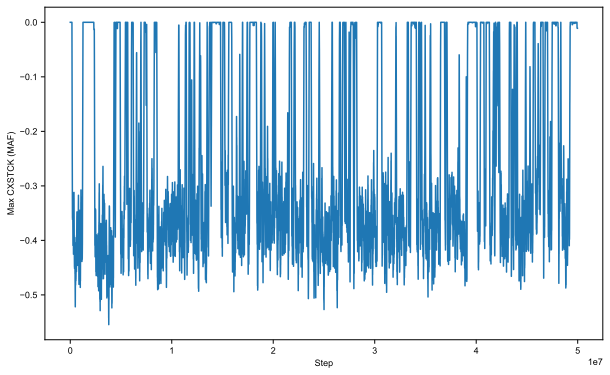

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))
for key in [("015", "2", "1")]:
    df = cxstack_MAF[key]
    ax.plot(df["step"], df["cxstack"], label=f"{key}")

ax.set_xlabel("Step")
ax.set_ylabel("Max CXSTCK (MAF)")

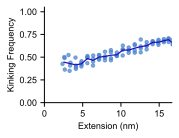

In [39]:
ZERO_TOL = 1e-9

records = []

for (k, r0, seed), df in cxstack_max_tables.items():
    mean_ext = mean_ext_by_key.get((k, r0, seed))
    if mean_ext is None:
        continue
    records.append({
        "r0": float(r0),
        "x": mean_ext,
        "y": float(np.mean(np.isclose(df["cxstack"], 0.0, atol=ZERO_TOL))),
    })

plot_df = pd.DataFrame(records)
mean_traj = plot_df.groupby("r0", as_index=False).agg({"x": "mean", "y": "mean"}).sort_values("x")

plt.figure(figsize=(2.5, 2))
plt.scatter(plot_df["x"], plot_df["y"], alpha=0.7, s=12, marker='o', color="#4a85cc")
plt.plot(mean_traj["x"], mean_traj["y"], color="#2308bd", lw=1.2)
plt.xlabel("Extension (nm)")
plt.ylabel("Kinking Frequency")
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.xlim(0, 16.65)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()


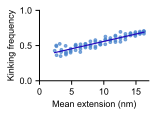

In [ ]:
ZERO_TOL = 1e-9
X_MAX = 16.5

records = []

for (k, r0, seed), df in cxstack_max_tables.items():
    mean_ext = mean_ext_by_key.get((k, r0, seed))
    if mean_ext is None:
        continue
    records.append({
        "x": mean_ext,
        "y": float(np.mean(np.isclose(df["cxstack"], 0.0, atol=ZERO_TOL))),
    })

plot_df = pd.DataFrame(records)
fit_df = plot_df[plot_df["x"] <= X_MAX].copy()

m, b = np.polyfit(fit_df["x"], fit_df["y"], 1)
x_line = np.linspace(fit_df["x"].min(), fit_df["x"].max(), 200)
y_line = m * x_line + b

plt.figure(figsize=(2.25, 1.7))
plt.scatter(fit_df["x"], fit_df["y"], alpha=0.7, s=8, marker='o', color="#4a85cc")
plt.plot(x_line, y_line, color="#2308bd", lw=1.2)
plt.xlabel("Mean extension (nm)")
plt.ylabel("Kinking frequency")
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.xlim(0, 17)
plt.xticks(np.arange(0, 18, 5))
plt.yticks(np.arange(0, 1, 0.25))
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


In [32]:
CUTOFF_STEP = 2.5e7


def steady_state_by_step(data_dict: dict, cutoff_step: float):
    steady = {}
    for key, df in data_dict.items():
        steady[key] = df[df["step"] >= cutoff_step].reset_index(drop=True)
    return steady


cxstack_ss = steady_state_by_step(cxstack_max_tables, CUTOFF_STEP)
mean_ext_ss_by_key = load_mean_extension_map(FEXT_FOLDER, CUTOFF_STEP)


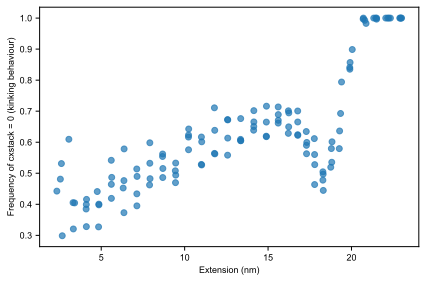

In [33]:
ZERO_TOL = 1e-9

x_vals = []
zero_freqs = []

for key, df in cxstack_ss.items():
    mean_ext = mean_ext_ss_by_key.get(key)
    if mean_ext is None:
        continue
    x_vals.append(mean_ext)
    zero_freqs.append(float(np.mean(np.isclose(df["cxstack"], 0.0, atol=ZERO_TOL))))

plt.figure(figsize=(6, 4))
plt.scatter(np.array(x_vals), zero_freqs, alpha=0.7)
plt.xlabel("Extension (nm)")
plt.ylabel("Frequency of cxstack = 0 (kinking behaviour)")
plt.tight_layout()
plt.show()
